<a href="https://colab.research.google.com/github/kallurigowrinandan736-eng/DAVP-project/blob/main/Ecommerce_Sales_and_Customer_Behaviour_Analysis_with_Outputs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E-Commerce Sales and Customer Behaviour Analysis Using Python
### End-to-end Data Analysis and Visualization Project



## 1. Scientific computing ecosystem



In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.max_columns", None)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Libraries imported successfully.")

NumPy: 2.3.5
Pandas: 2.2.3
Libraries imported successfully.


## 2. Load the e-commerce dataset



In [ ]:
# Update this to the path of your own CSV or Excel file.
DATA_PATH = None  # Example: "ecommerce_sales.csv" or "Online Retail.xlsx"

if DATA_PATH and os.path.exists(DATA_PATH):
    if DATA_PATH.lower().endswith((".xlsx", ".xls")):
        raw = pd.read_excel(DATA_PATH)
    elif DATA_PATH.lower().endswith(".json"):
        raw = pd.read_json(DATA_PATH)
    else:
        raw = pd.read_csv(DATA_PATH)
    DATA_SOURCE = "user-provided dataset"
else:
    # Reproducible demo data: use only when no real dataset path is supplied.
    rng = np.random.default_rng(42)
    n = 3200
    start = pd.Timestamp("2024-01-01")
    days = rng.integers(0, 365, size=n)
    customer_ids = rng.integers(1001, 1451, size=n)
    products = [
        ("P001", "Wireless Mouse", "Electronics", 18.0),
        ("P002", "USB-C Cable", "Electronics", 9.5),
        ("P003", "Water Bottle", "Home & Living", 14.0),
        ("P004", "Notebook Set", "Stationery", 7.0),
        ("P005", "Desk Lamp", "Home & Living", 29.0),
        ("P006", "Bluetooth Speaker", "Electronics", 42.0),
        ("P007", "Backpack", "Accessories", 35.0),
        ("P008", "Coffee Mug", "Home & Living", 11.0),
        ("P009", "Pen Pack", "Stationery", 5.0),
        ("P010", "Phone Stand", "Accessories", 12.0),
    ]
    product_idx = rng.choice(len(products), size=n, p=[.14,.15,.11,.12,.08,.07,.08,.09,.08,.08])
    rows = []
    for i in range(n):
        sku, product, category, base_price = products[product_idx[i]]
        qty = int(rng.choice([1, 2, 3, 4, 5], p=[.46,.27,.15,.08,.04]))
        price = round(max(1, rng.normal(base_price, base_price * .08)), 2)
        rows.append({
            "InvoiceNo": f"INV{100000+i}",
            "StockCode": sku,
            "Description": product,
            "Category": category,
            "Quantity": qty,
            "InvoiceDate": start + pd.Timedelta(days=int(days[i]), hours=int(rng.integers(8, 23)), minutes=int(rng.integers(0,60))),
            "UnitPrice": price,
            "CustomerID": int(customer_ids[i]),
            "Country": rng.choice(["United Kingdom", "Germany", "France", "Spain", "India", "Netherlands"], p=[.48,.14,.12,.09,.10,.07])
        })
    raw = pd.DataFrame(rows)
    # Add a few quality issues for demonstration of missing-value handling.
    missing_indices = rng.choice(raw.index, size=12, replace=False)
    raw.loc[missing_indices[:6], "CustomerID"] = np.nan
    raw.loc[missing_indices[6:], "Description"] = np.nan
    DATA_SOURCE = "generated demo dataset (illustrative only)"

print("Data source:", DATA_SOURCE)
print("Shape:", raw.shape)
display(raw.head())

Data source: generated demo dataset (illustrative only)
Shape: (3200, 9)


,InvoiceNo,StockCode,Description,Category,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,INV100000,P008,Coffee Mug,Home & Living,1,2024-02-02 09:00:00,12.00,1415.0,Germany
1,INV100001,P010,Phone Stand,Accessories,1,2024-10-09 17:57:00,13.49,1411.0,United Kingdom
2,INV100002,P009,Pen Pack,Stationery,2,2024-08-26 14:01:00,5.73,1347.0,Spain
3,INV100003,P006,Bluetooth Speaker,Electronics,1,2024-06-09 15:32:00,45.38,1064.0,United Kingdom
4,INV100004,P010,Phone Stand,Accessories,1,2024-06-07 09:52:00,10.89,1135.0,France


## 3. Understand the dataset and column meanings

| Column | Meaning | Why it matters |
|---|---|---|
| `InvoiceNo` | Order/invoice identifier | Counts orders and identifies transactions |
| `StockCode` | Product code | Helps count and compare products |
| `Description` | Product name | Makes product-level findings readable |
| `Category` | Product category, if available | Supports category comparisons; may be absent in some datasets |
| `Quantity` | Units sold in a transaction line | Measures item volume; negative values may represent returns |
| `InvoiceDate` | Date/time of transaction | Enables daily, monthly, and seasonal trends |
| `UnitPrice` | Price per unit | Used to calculate line revenue |
| `CustomerID` | Customer identifier | Enables repeat-purchase and customer segmentation analysis |
| `Country` | Customer/order country | Supports geographic sales analysis |
| `Sales` | Revenue, if already supplied | Some datasets provide sales directly rather than quantity and price |

Actual column names and definitions vary by source. The notebook standardizes common alternatives in the next step.

## 4. Standardize column names and prepare key fields

In [ ]:
data = raw.copy()

# Map common column-name variants to a consistent naming convention.
rename_map = {}
for col in data.columns:
    key = str(col).strip().lower().replace("_", " ").replace("-", " ")
    compact = " ".join(key.split())
    if compact in ["invoice", "invoice no", "invoice number", "order id", "order number", "order"]:
        rename_map[col] = "InvoiceNo"
    elif compact in ["stockcode", "stock code", "product id", "sku", "item id"]:
        rename_map[col] = "StockCode"
    elif compact in ["description", "product", "product name", "item name"]:
        rename_map[col] = "Description"
    elif compact in ["category", "product category"]:
        rename_map[col] = "Category"
    elif compact in ["quantity", "qty", "units"]:
        rename_map[col] = "Quantity"
    elif compact in ["invoicedate", "invoice date", "order date", "date", "transaction date"]:
        rename_map[col] = "InvoiceDate"
    elif compact in ["unitprice", "unit price", "price", "price per unit"]:
        rename_map[col] = "UnitPrice"
    elif compact in ["customerid", "customer id", "customer", "client id"]:
        rename_map[col] = "CustomerID"
    elif compact in ["country", "region", "market"]:
        rename_map[col] = "Country"
    elif compact in ["sales", "revenue", "total sales", "line total"]:
        rename_map[col] = "Sales"

data = data.rename(columns=rename_map)
print("Standardized columns:", data.columns.tolist())
print("Shape:", data.shape)
display(data.head())

Standardized columns: ['InvoiceNo', 'StockCode', 'Description', 'Category', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Shape: (3200, 9)


,InvoiceNo,StockCode,Description,Category,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,INV100000,P008,Coffee Mug,Home & Living,1,2024-02-02 09:00:00,12.00,1415.0,Germany
1,INV100001,P010,Phone Stand,Accessories,1,2024-10-09 17:57:00,13.49,1411.0,United Kingdom
2,INV100002,P009,Pen Pack,Stationery,2,2024-08-26 14:01:00,5.73,1347.0,Spain
3,INV100003,P006,Bluetooth Speaker,Electronics,1,2024-06-09 15:32:00,45.38,1064.0,United Kingdom
4,INV100004,P010,Phone Stand,Accessories,1,2024-06-07 09:52:00,10.89,1135.0,France


## 5. Inspect data types, shape, and basic structure

In [ ]:
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])
print("\nColumn data types:")
display(data.dtypes.to_frame("data_type"))
print("\nDataFrame information:")
data.info()
print("\nSummary preview:")
display(data.head())

Rows: 3200
Columns: 9

Column data types:


,data_type
InvoiceNo,object
StockCode,object
Description,object
Category,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object



DataFrame information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3200 entries, 0 to 3199
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    3200 non-null   object        
 1   StockCode    3200 non-null   object        
 2   Description  3194 non-null   object        
 3   Category     3200 non-null   object        
 4   Quantity     3200 non-null   int64         
 5   InvoiceDate  3200 non-null   datetime64[ns]
 6   UnitPrice    3200 non-null   float64       
 7   CustomerID   3194 non-null   float64       
 8   Country      3200 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(5)
memory usage: 225.1+ KB

Summary preview:


,InvoiceNo,StockCode,Description,Category,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,INV100000,P008,Coffee Mug,Home & Living,1,2024-02-02 09:00:00,12.00,1415.0,Germany
1,INV100001,P010,Phone Stand,Accessories,1,2024-10-09 17:57:00,13.49,1411.0,United Kingdom
2,INV100002,P009,Pen Pack,Stationery,2,2024-08-26 14:01:00,5.73,1347.0,Spain
3,INV100003,P006,Bluetooth Speaker,Electronics,1,2024-06-09 15:32:00,45.38,1064.0,United Kingdom
4,INV100004,P010,Phone Stand,Accessories,1,2024-06-07 09:52:00,10.89,1135.0,France


## 6. Data cleaning: missing values and duplicates



,missing_count,missing_percent
Description,6,0.19
CustomerID,6,0.19
InvoiceNo,0,0.00
Category,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


Total missing cells: 12
Exact duplicate rows: 0


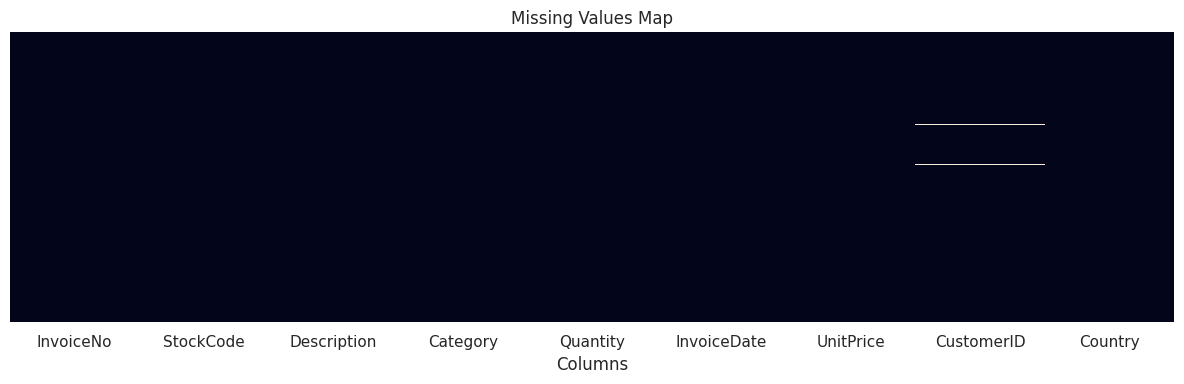

In [ ]:
# Convert common placeholder strings to actual missing values.
data = data.replace(["?", "NA", "N/A", "null", "None", ""], np.nan)

missing_summary = pd.DataFrame({
    "missing_count": data.isna().sum(),
    "missing_percent": (data.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)
display(missing_summary)
print("Total missing cells:", int(data.isna().sum().sum()))
print("Exact duplicate rows:", int(data.duplicated().sum()))

plt.figure(figsize=(12, 4))
sns.heatmap(data.isna(), cbar=False, yticklabels=False)
plt.title("Missing Values Map")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

In [ ]:
# Convert types safely
if "InvoiceDate" in data.columns:
    data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"], errors="coerce")
for col in ["Quantity", "UnitPrice", "Sales", "CustomerID"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove exact duplicate rows only.
before = len(data)
data = data.drop_duplicates().copy()
print("Rows before duplicate removal:", before)
print("Rows after duplicate removal:", len(data))

# If revenue is not supplied, calculate line sales = quantity × unit price.
if "Sales" not in data.columns and {"Quantity", "UnitPrice"}.issubset(data.columns):
    data["Sales"] = data["Quantity"] * data["UnitPrice"]
elif "Sales" in data.columns:
    data["Sales"] = pd.to_numeric(data["Sales"], errors="coerce")

# Keep a copy before optional imputation; missing CustomerID stays missing by design.
print("Missing values after type conversion:")
display(data.isna().sum().to_frame("missing_count"))

Rows before duplicate removal: 3200
Rows after duplicate removal: 3200
Missing values after type conversion:


,missing_count
InvoiceNo,0
StockCode,0
Description,6
Category,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,6
Country,0
Sales,0


### Missing-value handling strategy

In [ ]:
for col in ["Description", "Category", "Country", "StockCode", "InvoiceNo"]:
    if col in data.columns:
        data[col] = data[col].fillna("Unknown")

# Remove rows with missing essential sales fields.
essential = [c for c in ["Quantity", "UnitPrice", "Sales"] if c in data.columns]
if essential:
    data = data.dropna(subset=essential).copy()

# Date-based analysis requires a valid date.
if "InvoiceDate" in data.columns:
    print("Rows with invalid/missing dates:", int(data["InvoiceDate"].isna().sum()))

print("Rows available for general analysis:", len(data))
print("Missing cells remaining:")
display(data.isna().sum().to_frame("missing_count"))

Rows with invalid/missing dates: 0
Rows available for general analysis: 3200
Missing cells remaining:


,missing_count
InvoiceNo,0
StockCode,0
Description,0
Category,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,6
Country,0
Sales,0


## 7. Create useful analysis features

In [ ]:
# Revenue and date features
if "InvoiceDate" in data.columns:
    data["Year"] = data["InvoiceDate"].dt.year
    data["Month"] = data["InvoiceDate"].dt.month
    data["MonthName"] = data["InvoiceDate"].dt.strftime("%b")
    data["YearMonth"] = data["InvoiceDate"].dt.to_period("M").astype(str)
    data["DayOfWeek"] = data["InvoiceDate"].dt.day_name()

# Treat negative quantities or sales as possible returns/adjustments.
if "Quantity" in data.columns:
    data["IsReturnOrNegativeQty"] = data["Quantity"] < 0
if "Sales" in data.columns:
    data["IsNegativeSales"] = data["Sales"] < 0

display(data.head())
print("Negative quantity rows:", int(data["IsReturnOrNegativeQty"].sum()) if "IsReturnOrNegativeQty" in data.columns else "N/A")
print("Negative sales rows:", int(data["IsNegativeSales"].sum()) if "IsNegativeSales" in data.columns else "N/A")

,InvoiceNo,StockCode,Description,Category,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,Year,Month,MonthName,YearMonth,DayOfWeek,IsReturnOrNegativeQty,IsNegativeSales
0,INV100000,P008,Coffee Mug,Home & Living,1,2024-02-02 09:00:00,12.00,1415.0,Germany,12.00,2024,2,Feb,2024-02,Friday,False,False
1,INV100001,P010,Phone Stand,Accessories,1,2024-10-09 17:57:00,13.49,1411.0,United Kingdom,13.49,2024,10,Oct,2024-10,Wednesday,False,False
2,INV100002,P009,Pen Pack,Stationery,2,2024-08-26 14:01:00,5.73,1347.0,Spain,11.46,2024,8,Aug,2024-08,Monday,False,False
3,INV100003,P006,Bluetooth Speaker,Electronics,1,2024-06-09 15:32:00,45.38,1064.0,United Kingdom,45.38,2024,6,Jun,2024-06,Sunday,False,False
4,INV100004,P010,Phone Stand,Accessories,1,2024-06-07 09:52:00,10.89,1135.0,France,10.89,2024,6,Jun,2024-06,Friday,False,False


Negative quantity rows: 0
Negative sales rows: 0


## 8. NumPy: arrays, indexing, slicing, and operations



In [ ]:
numeric_cols = data.select_dtypes(include=np.number).columns.tolist()
numeric_array = data[numeric_cols].to_numpy()
print("Numeric array shape:", numeric_array.shape)
print("First row:", numeric_array[0])
print("First five rows, first three numeric columns:\n", numeric_array[:5, :3])
print("First five sales values:", data["Sales"].to_numpy()[:5])
print("First five sales values multiplied by 1.1:", (data["Sales"].to_numpy()[:5] * 1.1).round(2))
print("Mean sales using NumPy:", round(float(np.nanmean(data["Sales"].to_numpy())), 2))

Numeric array shape: (3200, 6)
First row: [1.000e+00 1.200e+01 1.415e+03 1.200e+01 2.024e+03 2.000e+00]
First five rows, first three numeric columns:
 [[1.000e+00 1.200e+01 1.415e+03]
 [1.000e+00 1.349e+01 1.411e+03]
 [2.000e+00 5.730e+00 1.347e+03]
 [1.000e+00 4.538e+01 1.064e+03]
 [1.000e+00 1.089e+01 1.135e+03]]
First five sales values: [12.   13.49 11.46 45.38 10.89]
First five sales values multiplied by 1.1: [13.2  14.84 12.61 49.92 11.98]
Mean sales using NumPy: 32.87


## 9. Pandas Series, DataFrames, indexing, and filtering

In [ ]:
sales_series = data["Sales"]
print("Series type:", type(sales_series))
display(sales_series.head())

cols_to_show = [c for c in ["InvoiceNo", "Description", "Quantity", "UnitPrice", "Sales", "CustomerID"] if c in data.columns]
display(data[cols_to_show].head())

print("Label-based selection:")
display(data.loc[:4, cols_to_show])
print("Position-based selection:")
display(data.iloc[:5, :min(5, data.shape[1])])

# Example filter: high-value line items (top 10% sales threshold)
threshold = data["Sales"].quantile(0.90)
high_value_lines = data[data["Sales"] >= threshold]
print("90th percentile sales threshold:", round(float(threshold), 2))
print("High-value transaction lines:", len(high_value_lines))
display(high_value_lines.head())

Series type: <class 'pandas.core.series.Series'>


0    12.00
1    13.49
2    11.46
3    45.38
4    10.89
Name: Sales, dtype: float64

,InvoiceNo,Description,Quantity,UnitPrice,Sales,CustomerID
0,INV100000,Coffee Mug,1,12.00,12.00,1415.0
1,INV100001,Phone Stand,1,13.49,13.49,1411.0
2,INV100002,Pen Pack,2,5.73,11.46,1347.0
3,INV100003,Bluetooth Speaker,1,45.38,45.38,1064.0
4,INV100004,Phone Stand,1,10.89,10.89,1135.0


Label-based selection:


,InvoiceNo,Description,Quantity,UnitPrice,Sales,CustomerID
0,INV100000,Coffee Mug,1,12.00,12.00,1415.0
1,INV100001,Phone Stand,1,13.49,13.49,1411.0
2,INV100002,Pen Pack,2,5.73,11.46,1347.0
3,INV100003,Bluetooth Speaker,1,45.38,45.38,1064.0
4,INV100004,Phone Stand,1,10.89,10.89,1135.0


Position-based selection:


,InvoiceNo,StockCode,Description,Category,Quantity
0,INV100000,P008,Coffee Mug,Home & Living,1
1,INV100001,P010,Phone Stand,Accessories,1
2,INV100002,P009,Pen Pack,Stationery,2
3,INV100003,P006,Bluetooth Speaker,Electronics,1
4,INV100004,P010,Phone Stand,Accessories,1


90th percentile sales threshold: 74.22
High-value transaction lines: 320


,InvoiceNo,StockCode,Description,Category,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales,Year,Month,MonthName,YearMonth,DayOfWeek,IsReturnOrNegativeQty,IsNegativeSales
23,INV100023,P007,Backpack,Accessories,3,2024-12-04 12:50:00,35.67,1350.0,United Kingdom,107.01,2024,12,Dec,2024-12,Wednesday,False,False
26,INV100026,P007,Backpack,Accessories,3,2024-05-26 21:56:00,32.64,1261.0,United Kingdom,97.92,2024,5,May,2024-05,Sunday,False,False
62,INV100062,P001,Wireless Mouse,Electronics,5,2024-05-13 15:31:00,18.95,1334.0,Germany,94.75,2024,5,May,2024-05,Monday,False,False
71,INV100071,P005,Desk Lamp,Home & Living,4,2024-03-10 14:28:00,31.47,1186.0,United Kingdom,125.88,2024,3,Mar,2024-03,Sunday,False,False
74,INV100074,P007,Backpack,Accessories,2,2024-09-07 12:37:00,38.23,1110.0,Netherlands,76.46,2024,9,Sep,2024-09,Saturday,False,False


## 10. Descriptive statistics and sales KPIs

We calculate transaction-line revenue, units, average order value, number of orders, and customer counts. If invoice identifiers are available, order-level metrics are computed from them.

In [ ]:
print("Descriptive statistics:")
display(data[[c for c in ["Quantity", "UnitPrice", "Sales"] if c in data.columns]].describe().T)

total_sales = data["Sales"].sum()
total_units = data["Quantity"].sum() if "Quantity" in data.columns else np.nan
order_count = data["InvoiceNo"].nunique() if "InvoiceNo" in data.columns else np.nan
customer_count = data["CustomerID"].nunique() if "CustomerID" in data.columns else np.nan

if "InvoiceNo" in data.columns:
    order_sales = data.groupby("InvoiceNo")["Sales"].sum()
    average_order_value = order_sales.mean()
else:
    order_sales = pd.Series(dtype=float)
    average_order_value = np.nan

kpis = pd.DataFrame({
    "Metric": ["Total revenue (net of negative rows)", "Total units", "Unique orders", "Identified customers", "Average order value"],
    "Value": [round(float(total_sales), 2), round(float(total_units), 2) if pd.notna(total_units) else np.nan,
              int(order_count) if pd.notna(order_count) else np.nan,
              int(customer_count) if pd.notna(customer_count) else np.nan,
              round(float(average_order_value), 2) if pd.notna(average_order_value) else np.nan]
})
display(kpis)

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Quantity,3200.0,1.965313,1.142155,1.00,1.0000,2.000,3.0000,5.00
UnitPrice,3200.0,16.634356,11.078858,3.70,9.0600,12.265,19.1925,52.42
Sales,3200.0,32.868234,31.402493,3.85,12.0075,21.780,39.3525,214.15


,Metric,Value
0,Total revenue (net of negative rows),105178.35
1,Total units,6289.00
2,Unique orders,3200.00
3,Identified customers,449.00
4,Average order value,32.87


## 11. Product and category performance

Top 10 products by revenue:


,units_sold,revenue,transaction_lines
Description,,,
Bluetooth Speaker,437,18218.30,230
Backpack,489,17247.55,242
Wireless Mouse,914,16415.72,455
Desk Lamp,504,14753.22,248
Water Bottle,710,9941.62,353
USB-C Cable,976,9307.60,508
Coffee Mug,563,6258.23,281
Notebook Set,805,5618.03,403
Phone Stand,414,4953.91,215


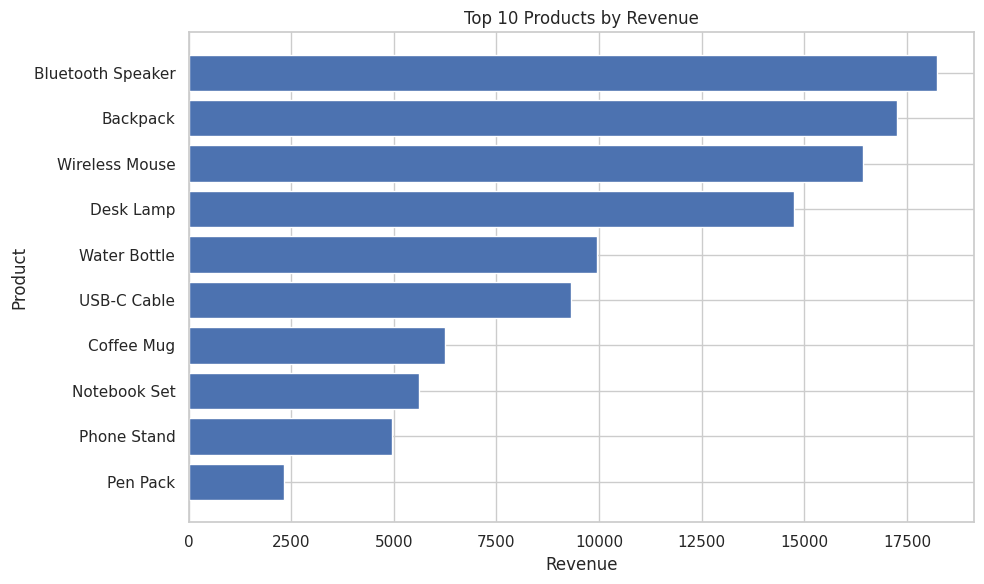

,units_sold,revenue,transaction_lines
Category,,,
Electronics,2334,44035.41,1196
Home & Living,1779,30978.58,884
Accessories,903,22201.46,457
Stationery,1273,7962.90,663


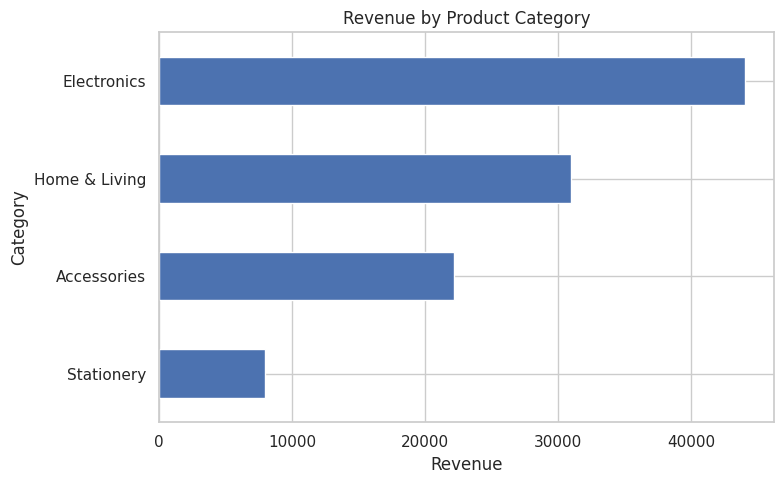

In [ ]:
if "Description" in data.columns:
    product_summary = data.groupby("Description", dropna=False).agg(
        units_sold=("Quantity", "sum"),
        revenue=("Sales", "sum"),
        transaction_lines=("Sales", "size")
    ).sort_values("revenue", ascending=False)
    print("Top 10 products by revenue:")
    display(product_summary.head(10))

    top_products = product_summary.head(10).sort_values("revenue")
    plt.figure(figsize=(10, 6))
    plt.barh(top_products.index.astype(str), top_products["revenue"])
    plt.title("Top 10 Products by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

if "Category" in data.columns:
    category_summary = data.groupby("Category").agg(
        units_sold=("Quantity", "sum"),
        revenue=("Sales", "sum"),
        transaction_lines=("Sales", "size")
    ).sort_values("revenue", ascending=False)
    display(category_summary)
    category_summary["revenue"].sort_values().plot(kind="barh", figsize=(8, 5))
    plt.title("Revenue by Product Category")
    plt.xlabel("Revenue")
    plt.tight_layout()
    plt.show()
else:
    print("No Category column found. Category-level analysis is skipped; product-level analysis remains available.")

## 12. Sales trends over time

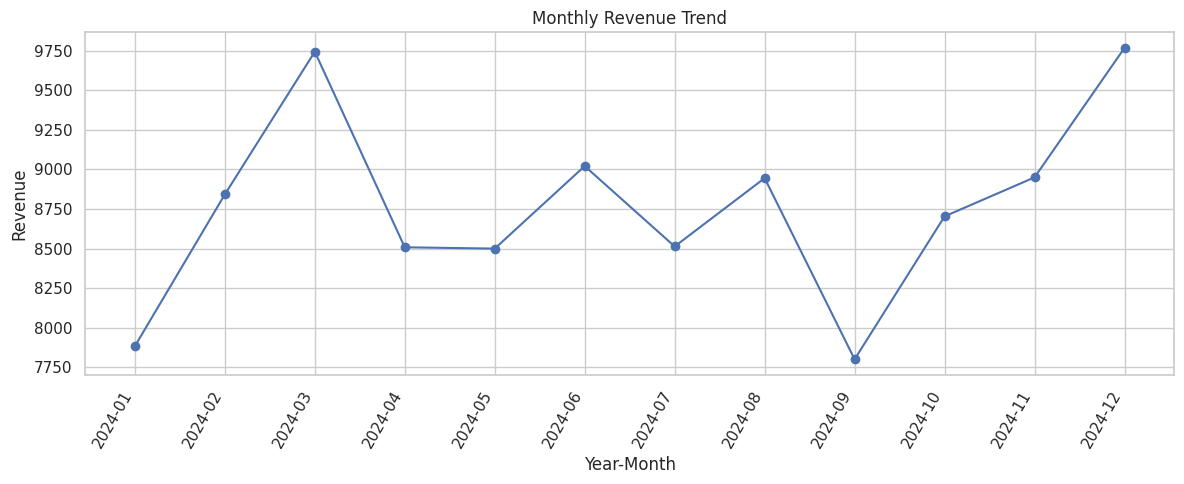

,YearMonth,Sales
0,2024-01,7883.68
1,2024-02,8841.96
2,2024-03,9743.28
3,2024-04,8508.35
4,2024-05,8499.94
5,2024-06,9021.00
6,2024-07,8513.55
7,2024-08,8944.91
8,2024-09,7801.15
9,2024-10,8703.55


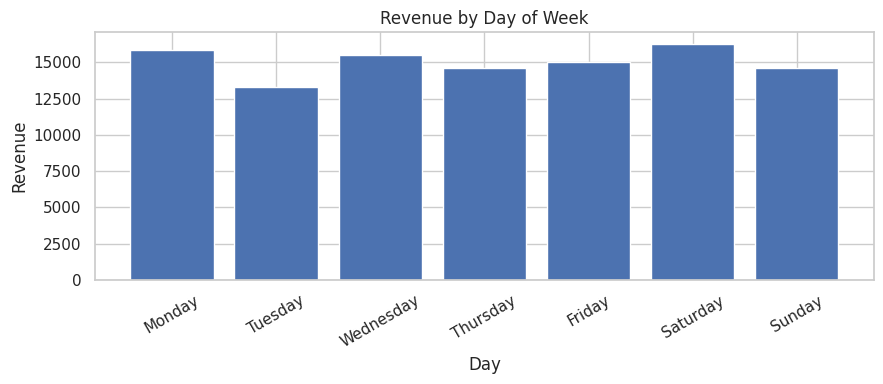

In [ ]:
if "InvoiceDate" in data.columns:
    dated = data.dropna(subset=["InvoiceDate"]).copy()
    monthly_sales = dated.groupby("YearMonth", as_index=False)["Sales"].sum()
    plt.figure(figsize=(12, 5))
    plt.plot(monthly_sales["YearMonth"], monthly_sales["Sales"], marker="o")
    plt.title("Monthly Revenue Trend")
    plt.xlabel("Year-Month")
    plt.ylabel("Revenue")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
    display(monthly_sales)

    weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
    weekday_sales = dated.groupby("DayOfWeek")["Sales"].sum().reindex(weekday_order)
    plt.figure(figsize=(9, 4))
    plt.bar(weekday_sales.index, weekday_sales.values)
    plt.title("Revenue by Day of Week")
    plt.xlabel("Day")
    plt.ylabel("Revenue")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No usable date column: time-series analysis is skipped.")

## 13. Customer behaviour analysis

Customer analysis can reveal repeat purchases and spending differences. Rows without a customer ID remain part of overall sales, but cannot be assigned to a customer.

Top 10 customers by spend:


,total_spend,order_count,total_units,transaction_lines
CustomerID,,,,
1419.0,713.15,13,27,13
1383.0,649.59,13,32,13
1342.0,630.47,14,27,14
1135.0,586.50,9,21,9
1275.0,579.34,9,23,9
1393.0,576.87,11,27,11
1113.0,572.98,9,22,9
1159.0,571.55,16,32,16
1068.0,565.48,11,29,11


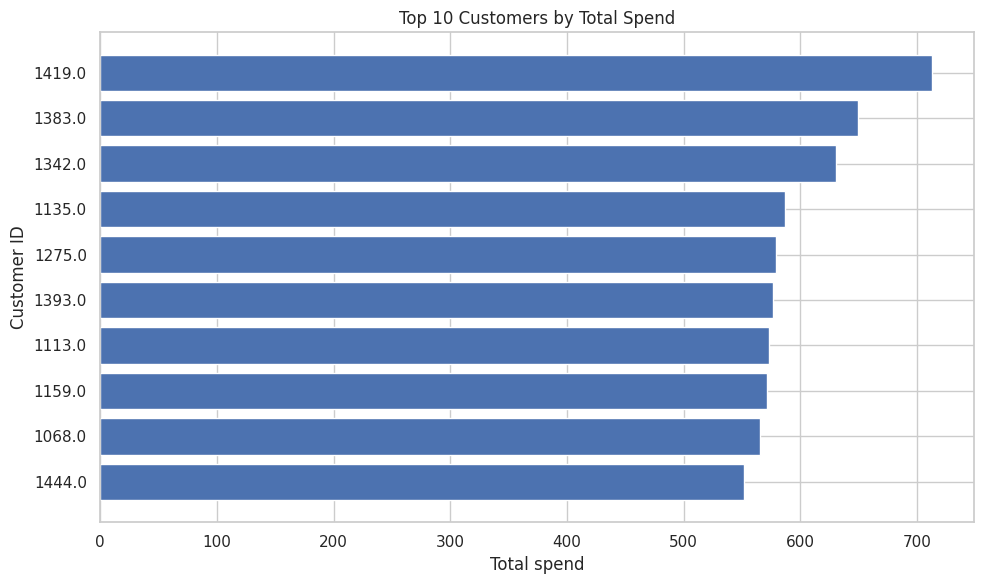

Identified customers with more than one order: 98.66%


In [ ]:
if "CustomerID" in data.columns:
    customer_data = data.dropna(subset=["CustomerID"]).copy()
    customer_data["CustomerID"] = customer_data["CustomerID"].astype(str)
    customer_summary = customer_data.groupby("CustomerID").agg(
        total_spend=("Sales", "sum"),
        order_count=("InvoiceNo", "nunique") if "InvoiceNo" in customer_data.columns else ("Sales", "size"),
        total_units=("Quantity", "sum"),
        transaction_lines=("Sales", "size")
    ).sort_values("total_spend", ascending=False)

    print("Top 10 customers by spend:")
    display(customer_summary.head(10))

    top_customers = customer_summary.head(10).sort_values("total_spend")
    plt.figure(figsize=(10, 6))
    plt.barh(top_customers.index, top_customers["total_spend"])
    plt.title("Top 10 Customers by Total Spend")
    plt.xlabel("Total spend")
    plt.ylabel("Customer ID")
    plt.tight_layout()
    plt.show()

    repeat_share = (customer_summary["order_count"] > 1).mean() * 100
    print(f"Identified customers with more than one order: {repeat_share:.2f}%")
else:
    customer_summary = pd.DataFrame()
    print("No CustomerID column found. Customer-level analysis is skipped.")

## 14. RFM customer segmentation

RFM stands for **Recency, Frequency, and Monetary value**:
- **Recency:** days since a customer's most recent order (lower is better).
- **Frequency:** number of distinct orders.
- **Monetary:** total spend.

This simple rule-based segmentation is a business-analysis technique, not a machine-learning model. It requires customer IDs, order identifiers, dates, and sales values.

RFM sample:


,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment
CustomerID,,,,,,,,
1419.0,44,13,713.15,2,4,4,244,Regular
1383.0,54,13,649.59,2,4,4,244,Regular
1342.0,34,14,630.47,2,4,4,244,Regular
1135.0,34,9,586.50,3,4,4,344,High-value
1275.0,2,9,579.34,4,4,4,444,High-value
1393.0,12,11,576.87,4,4,4,444,High-value
1113.0,14,9,572.98,4,3,4,434,High-value
1159.0,28,16,571.55,3,4,4,344,High-value
1068.0,28,11,565.48,3,4,4,344,High-value


,customers
Segment,
At-risk / inactive,133
Regular,133
High-value,100
Loyal / active,83


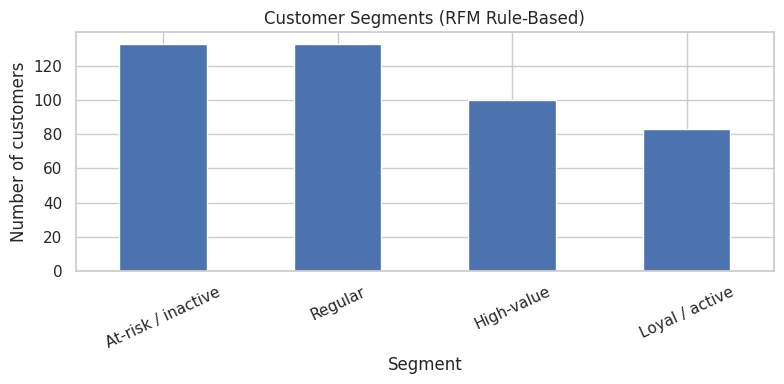

In [ ]:
rfm = pd.DataFrame()
if all(c in data.columns for c in ["CustomerID", "InvoiceNo", "InvoiceDate", "Sales"]):
    rfm_data = data.dropna(subset=["CustomerID", "InvoiceNo", "InvoiceDate"]).copy()
    rfm_data["CustomerID"] = rfm_data["CustomerID"].astype(str)
    snapshot_date = rfm_data["InvoiceDate"].max() + pd.Timedelta(days=1)
    rfm = rfm_data.groupby("CustomerID").agg(
        Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Sales", "sum")
    )

    # Rank customers into quartiles where possible; handle small/constant groups robustly.
    def score_quartiles(series, reverse=False):
        ranks = series.rank(method="first", ascending=True)
        scores = pd.qcut(ranks, q=min(4, len(ranks)), labels=False, duplicates="drop") + 1
        scores = scores.astype(int)
        if reverse:
            scores = scores.max() + 1 - scores
        return scores

    if len(rfm) >= 4:
        rfm["R_score"] = score_quartiles(rfm["Recency"], reverse=True)
        rfm["F_score"] = score_quartiles(rfm["Frequency"])
        rfm["M_score"] = score_quartiles(rfm["Monetary"])
        rfm["RFM_score"] = rfm[["R_score", "F_score", "M_score"]].astype(str).agg("".join, axis=1)

        def segment(row):
            if row["R_score"] >= 3 and row["F_score"] >= 3 and row["M_score"] >= 3:
                return "High-value"
            if row["R_score"] >= 3 and row["F_score"] >= 2:
                return "Loyal / active"
            if row["R_score"] <= 2 and row["F_score"] <= 2:
                return "At-risk / inactive"
            return "Regular"

        rfm["Segment"] = rfm.apply(segment, axis=1)
        print("RFM sample:")
        display(rfm.sort_values("Monetary", ascending=False).head(10))
        segment_counts = rfm["Segment"].value_counts()
        display(segment_counts.to_frame("customers"))

        plt.figure(figsize=(8, 4))
        segment_counts.plot(kind="bar")
        plt.title("Customer Segments (RFM Rule-Based)")
        plt.xlabel("Segment")
        plt.ylabel("Number of customers")
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()
    else:
        print("Not enough identified customers for quartile-based RFM segmentation.")
else:
    print("RFM requires CustomerID, InvoiceNo, InvoiceDate, and Sales columns.")

## 15. Country or market analysis

,revenue,orders,customers
Country,,,
United Kingdom,50265.42,1522,434
Germany,15097.20,457,300
France,12538.21,399,261
India,10084.44,304,218
Spain,9731.42,303,223
Netherlands,7461.66,215,172


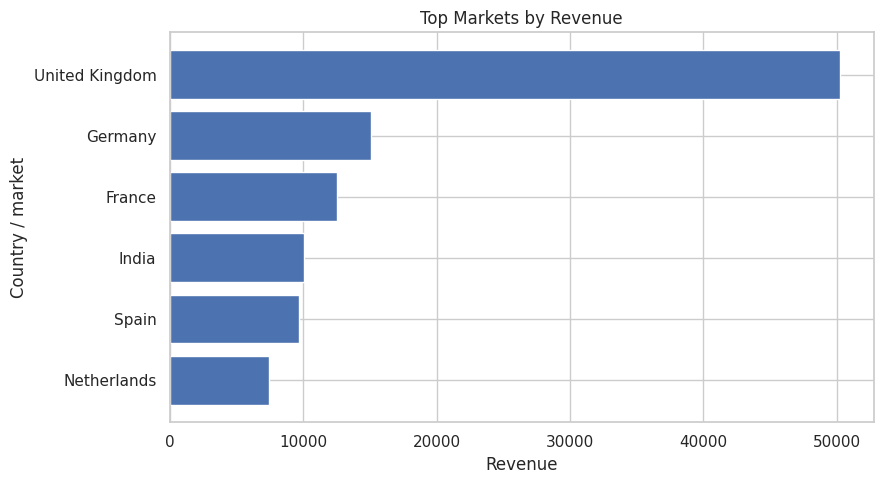

In [ ]:
if "Country" in data.columns:
    country_summary = data.groupby("Country").agg(
        revenue=("Sales", "sum"),
        orders=("InvoiceNo", "nunique") if "InvoiceNo" in data.columns else ("Sales", "size"),
        customers=("CustomerID", "nunique") if "CustomerID" in data.columns else ("Sales", "size")
    ).sort_values("revenue", ascending=False)
    display(country_summary.head(10))

    top_countries = country_summary.head(10).sort_values("revenue")
    plt.figure(figsize=(9, 5))
    plt.barh(top_countries.index.astype(str), top_countries["revenue"])
    plt.title("Top Markets by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Country / market")
    plt.tight_layout()
    plt.show()
else:
    print("No Country/market column found; geographic analysis is skipped.")

## 16. Outlier detection using the IQR method

The IQR rule flags potential outliers; it does not prove that a transaction is wrong. Large orders may be legitimate, while negative quantities or sales may indicate returns or adjustments. Inspect the records before removing them.

,column,Q1,Q3,IQR,lower_bound,upper_bound,potential_outliers
0,Quantity,1.00,3.00,2.00,-2.00,6.00,0
1,UnitPrice,9.06,19.19,10.13,-6.14,34.39,371
2,Sales,12.01,39.35,27.34,-29.01,80.37,263


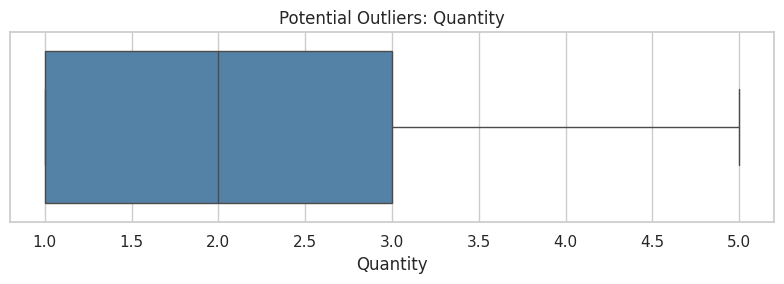

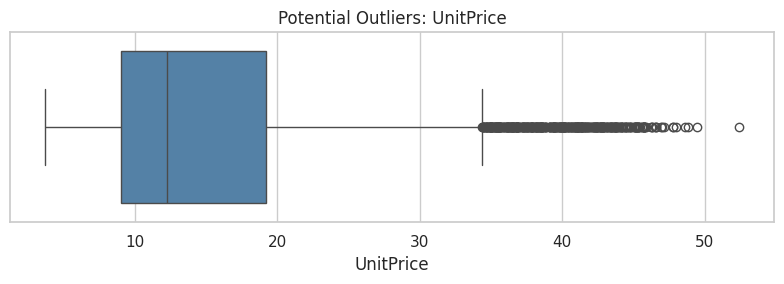

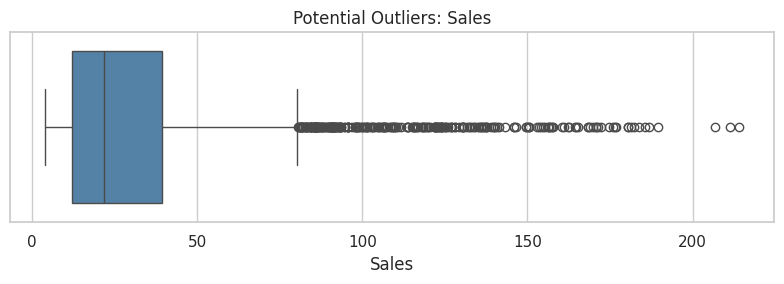

In [ ]:
outlier_summary = []
for col in [c for c in ["Quantity", "UnitPrice", "Sales"] if c in data.columns]:
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr_value = q3 - q1
    low, high = q1 - 1.5 * iqr_value, q3 + 1.5 * iqr_value
    mask = (data[col] < low) | (data[col] > high)
    outlier_summary.append({
        "column": col, "Q1": q1, "Q3": q3, "IQR": iqr_value,
        "lower_bound": low, "upper_bound": high,
        "potential_outliers": int(mask.sum())
    })
display(pd.DataFrame(outlier_summary).round(2))

for col in [c for c in ["Quantity", "UnitPrice", "Sales"] if c in data.columns]:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=data[col], color="steelblue")
    plt.title(f"Potential Outliers: {col}")
    plt.tight_layout()
    plt.show()

## 17. Correlation and covariance

Correlation measures linear association from −1 to +1; covariance depends on variable scale. We use numeric sales features only. These statistics can be influenced by skewed transaction values and do not imply causation.

Correlation matrix:


,Quantity,UnitPrice,Sales
Quantity,1.000,0.014,0.617
UnitPrice,0.014,1.000,0.692
Sales,0.617,0.692,1.000


Covariance matrix:


,Quantity,UnitPrice,Sales
Quantity,1.305,0.177,22.137
UnitPrice,0.177,122.741,240.723
Sales,22.137,240.723,986.117


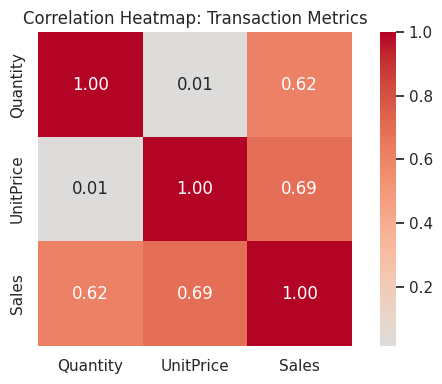

In [ ]:
corr_cols = [c for c in ["Quantity", "UnitPrice", "Sales"] if c in data.columns]
corr_matrix = data[corr_cols].corr()
cov_matrix = data[corr_cols].cov()
print("Correlation matrix:")
display(corr_matrix.round(3))
print("Covariance matrix:")
display(cov_matrix.round(3))

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation Heatmap: Transaction Metrics")
plt.tight_layout()
plt.show()

## 18. Feature relationships and pattern identification

Compare quantity and unit price against sales, and inspect average basket/order value. These visuals help identify patterns that may need further business investigation.

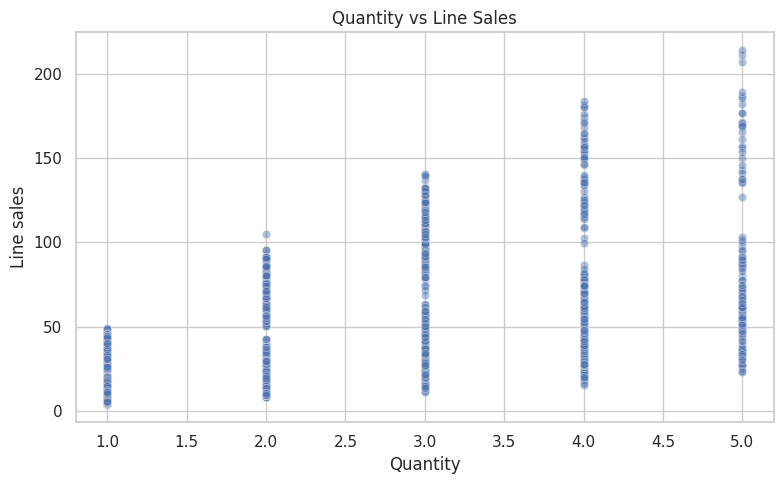

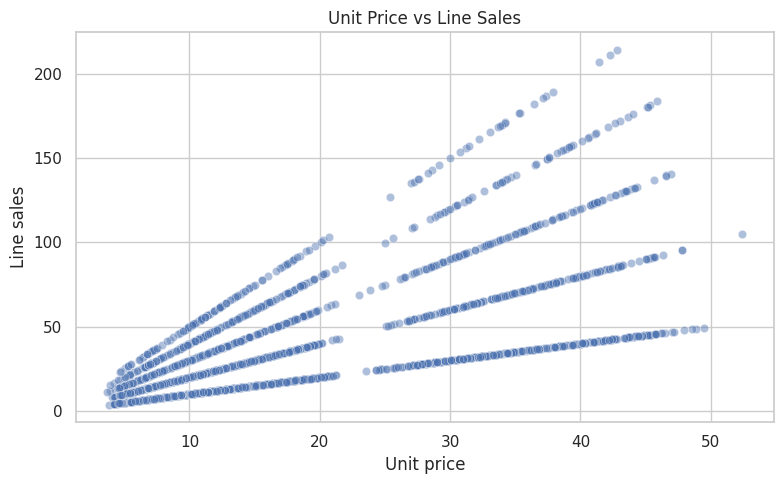

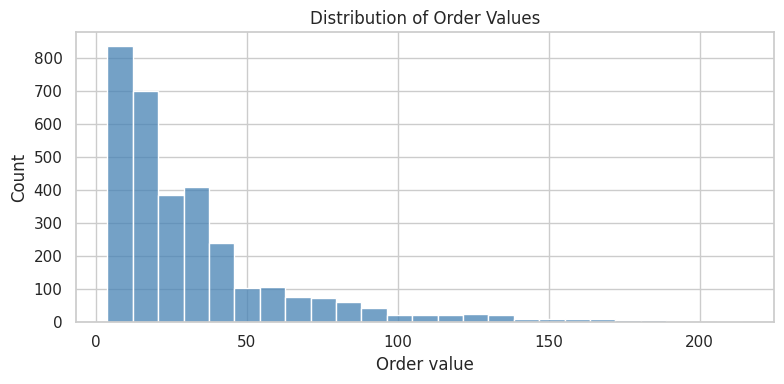

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="Quantity", y="Sales", alpha=0.45)
plt.title("Quantity vs Line Sales")
plt.xlabel("Quantity")
plt.ylabel("Line sales")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(data=data, x="UnitPrice", y="Sales", alpha=0.45)
plt.title("Unit Price vs Line Sales")
plt.xlabel("Unit price")
plt.ylabel("Line sales")
plt.tight_layout()
plt.show()

if "InvoiceNo" in data.columns:
    order_totals = data.groupby("InvoiceNo", as_index=False)["Sales"].sum()
    plt.figure(figsize=(8, 4))
    sns.histplot(order_totals["Sales"], bins=25, color="steelblue")
    plt.title("Distribution of Order Values")
    plt.xlabel("Order value")
    plt.tight_layout()
    plt.show()

## 19. Matplotlib: line, bar, histogram, and scatter plots

This section demonstrates foundational plotting and customization: titles, labels, legends, grids, tick labels, and figure sizing.

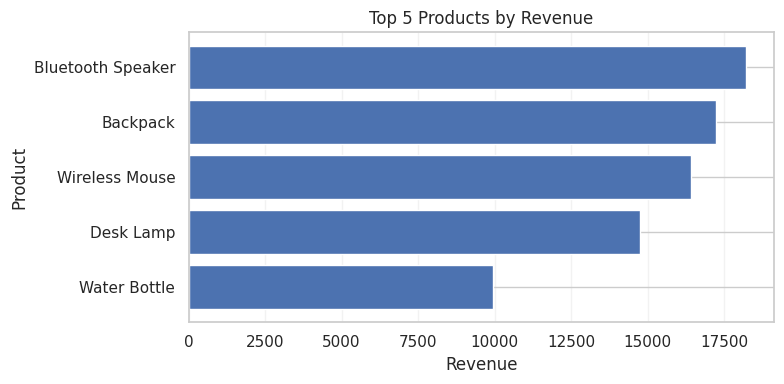

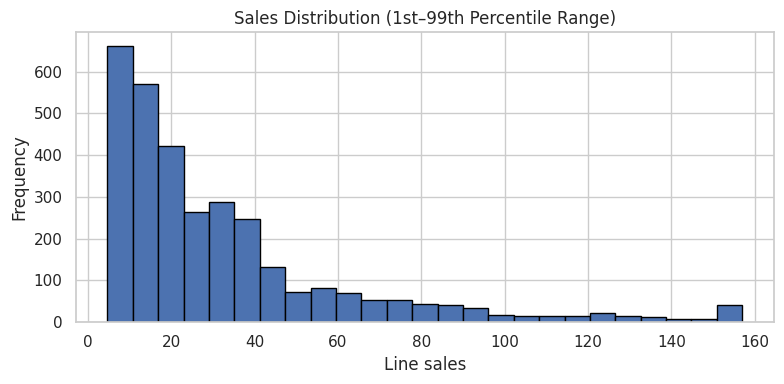

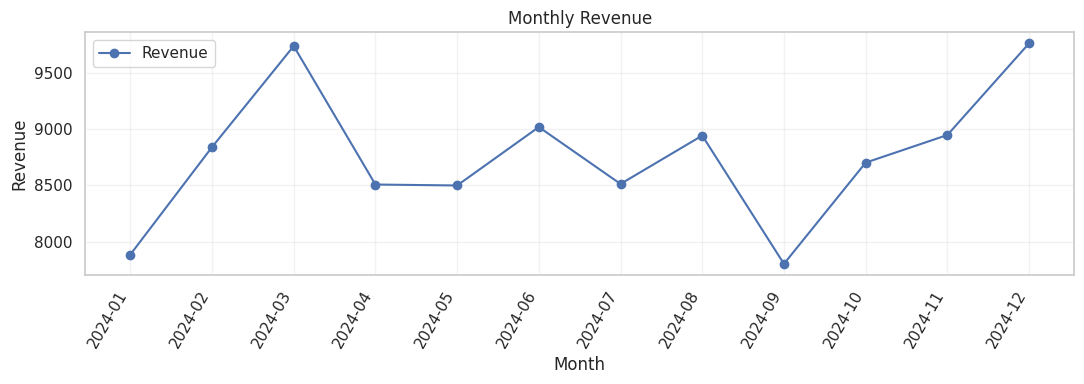

In [ ]:
# Bar: top five products by revenue
if "Description" in data.columns:
    top5 = data.groupby("Description")["Sales"].sum().nlargest(5).sort_values()
    plt.figure(figsize=(8, 4))
    plt.barh(top5.index, top5.values)
    plt.title("Top 5 Products by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Product")
    plt.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

# Histogram: sales distribution
plt.figure(figsize=(8, 4))
plt.hist(data["Sales"].clip(lower=data["Sales"].quantile(0.01), upper=data["Sales"].quantile(0.99)),
         bins=25, edgecolor="black")
plt.title("Sales Distribution (1st–99th Percentile Range)")
plt.xlabel("Line sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Line plot: monthly revenue if dates exist
if "YearMonth" in data.columns:
    month_series = data.groupby("YearMonth")["Sales"].sum()
    plt.figure(figsize=(11, 4))
    plt.plot(month_series.index, month_series.values, marker="o", label="Revenue")
    plt.title("Monthly Revenue")
    plt.xlabel("Month")
    plt.ylabel("Revenue")
    plt.xticks(rotation=60, ha="right")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 20. Advanced Seaborn visualizations

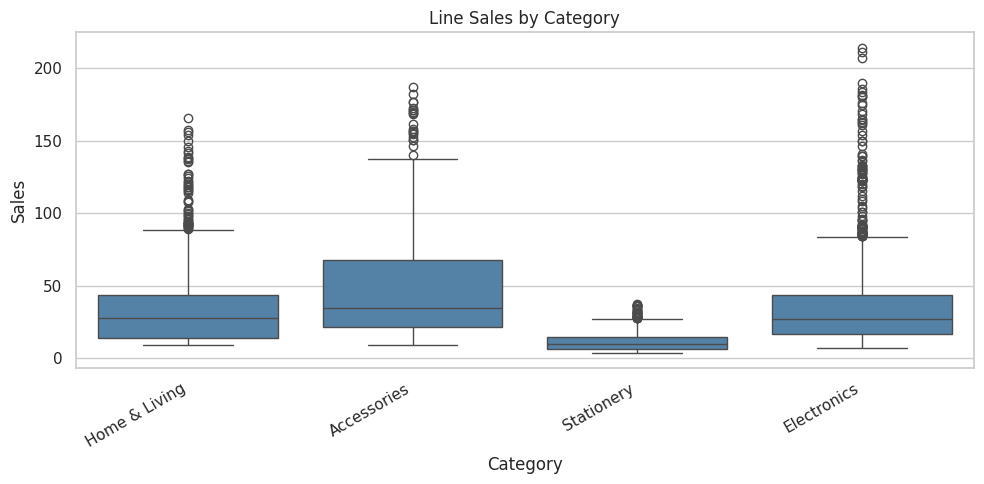

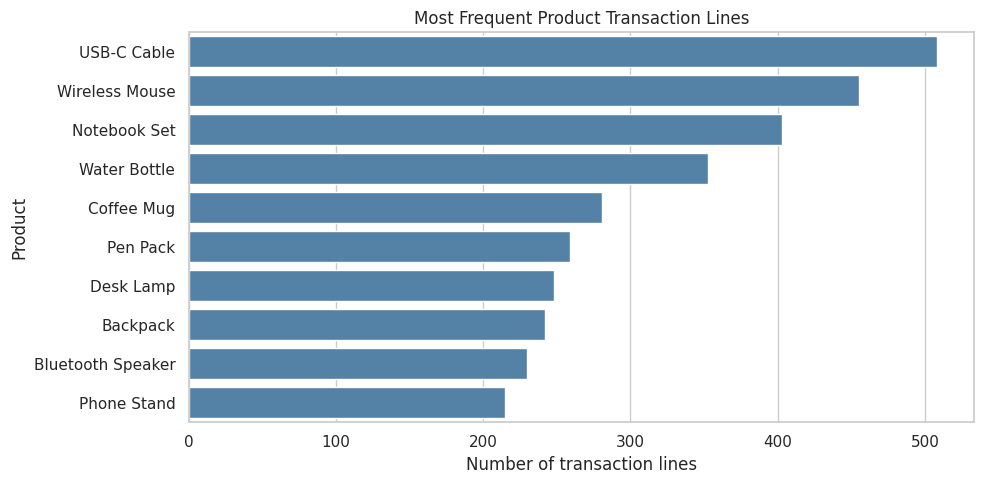

In [ ]:
# Distribution of sales by category, if available
if "Category" in data.columns:
    top_categories = data["Category"].value_counts().head(8).index
    plot_data = data[data["Category"].isin(top_categories)].copy()
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=plot_data, x="Category", y="Sales", color="steelblue")
    plt.title("Line Sales by Category")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

# Countplot: most frequently occurring product descriptions
if "Description" in data.columns:
    top_desc = data["Description"].value_counts().head(10).index
    plt.figure(figsize=(10, 5))
    sns.countplot(data=data[data["Description"].isin(top_desc)], y="Description",
                  order=top_desc, color="steelblue")
    plt.title("Most Frequent Product Transaction Lines")
    plt.xlabel("Number of transaction lines")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.show()

## 21. Interactive Plotly charts

In [ ]:
fig = px.scatter(
    data, x="Quantity", y="Sales",
    color="Category" if "Category" in data.columns else None,
    hover_data=[c for c in ["Description", "UnitPrice", "Country", "CustomerID"] if c in data.columns],
    title="Interactive: Quantity vs Sales"
)
fig.show()

if "YearMonth" in data.columns:
    monthly_plot = data.groupby("YearMonth", as_index=False)["Sales"].sum()
    fig = px.line(monthly_plot, x="YearMonth", y="Sales", markers=True,
                  title="Interactive Monthly Revenue Trend")
    fig.show()

if "Description" in data.columns:
    product_plot = data.groupby("Description", as_index=False)["Sales"].sum().nlargest(10, "Sales")
    fig = px.bar(product_plot, x="Sales", y="Description", orientation="h",
                 title="Interactive Top 10 Products by Revenue")
    fig.show()

## 22. Simple interactive dashboard

This Plotly chart is interactive: hover for values, zoom, and toggle legend items. Change `dashboard_metric` to view another metric.

In [ ]:
dashboard_metric = "Sales"  # Try "Quantity" or "UnitPrice"
fig = px.histogram(
    data, x=dashboard_metric,
    color="Category" if "Category" in data.columns else None,
    marginal="box", title=f"Dashboard: {dashboard_metric} distribution",
    opacity=0.75
)
fig.show()
print("Dashboard metric:", dashboard_metric)

Dashboard metric: Sales


## 23. Automated business summary

The following cell prints key indicators from the dataset loaded above. Read the numbers in context, especially if the notebook is using generated demo data.

In [ ]:
print("E-COMMERCE PROJECT SUMMARY")
print("=" * 55)
print("Data source:", DATA_SOURCE)
print("Rows analyzed:", len(data))
print("Columns available:", len(data.columns))
print("Missing cells remaining:", int(data.isna().sum().sum()))
print("Duplicate rows remaining:", int(data.duplicated().sum()))
print(f"Total revenue (net): {data['Sales'].sum():,.2f}")
print(f"Total units (net): {data['Quantity'].sum():,.0f}" if "Quantity" in data.columns else "Quantity unavailable")
print(f"Unique orders: {data['InvoiceNo'].nunique():,}" if "InvoiceNo" in data.columns else "Order identifier unavailable")
print(f"Identified customers: {data['CustomerID'].nunique():,}" if "CustomerID" in data.columns else "Customer identifier unavailable")
if "InvoiceNo" in data.columns:
    print(f"Average order value: {data.groupby('InvoiceNo')['Sales'].sum().mean():,.2f}")
if "Description" in data.columns:
    print("\nTop product by revenue:")
    display(data.groupby("Description")["Sales"].sum().sort_values(ascending=False).head(1).to_frame("revenue"))
if "YearMonth" in data.columns:
    print("\nTop month by revenue:")
    display(data.groupby("YearMonth")["Sales"].sum().sort_values(ascending=False).head(1).to_frame("revenue"))
if len(rfm) and "Segment" in rfm.columns:
    print("\nRFM segment counts:")
    display(rfm["Segment"].value_counts().to_frame("customers"))

E-COMMERCE PROJECT SUMMARY
Data source: generated demo dataset (illustrative only)
Rows analyzed: 3200
Columns available: 17
Missing cells remaining: 6
Duplicate rows remaining: 0
Total revenue (net): 105,178.35
Total units (net): 6,289
Unique orders: 3,200
Identified customers: 449
Average order value: 32.87

Top product by revenue:


,revenue
Description,
Bluetooth Speaker,18218.3



Top month by revenue:


,revenue
YearMonth,
2024-12,9767.19



RFM segment counts:


,customers
Segment,
At-risk / inactive,133
Regular,133
High-value,100
Loyal / active,83


## 24. Data storytelling: report and presentation guide

Use this sequence when explaining the project:

1. **Business problem:** The store needs to understand sales, products, and customer purchasing behaviour.
2. **Dataset:** State the source, date range, number of rows, columns, and definitions.
3. **Data quality:** Report missing values, duplicates, invalid dates, and how you treated returns.
4. **Sales performance:** Present total revenue, units sold, orders, and average order value.
5. **Product performance:** Show best-selling products and categories.
6. **Customer behaviour:** Discuss repeat purchases, top spenders, and RFM segments if the data supports them.
7. **Trends:** Explain monthly or weekday patterns visible in the charts.
8. **Recommendations:** For example, investigate strong categories, encourage repeat purchases, and review high-return products—but only when supported by results.
9. **Limitations:** Results depend on the dataset, missing customer IDs limit customer-level analysis, and correlation does not prove causation.

### Final checklist
- Replace demo data with your actual or documented real-world dataset before submitting.
- Confirm all column definitions and currency units.
- Run **Kernel → Restart Kernel and Run All Cells**.
- Include screenshots of the KPI table, monthly sales chart, top products, customer segmentation, and correlation heatmap in your report.